# Analysis of 2026 pastry data
The following bakeries were included:
- `Bread Chic`
- `La Creperie`
- `Phillippe`
- `Trickster`
- `Little Bird`

In addition, the following negative controls were used:
- `Lamar donut (regular)`
- `Lamar donut (cake)`
- `King Soopers`
- `Bread (homemade)`

### Metrics
The metrics from the analysis in `2024` are carried over and augmented with a new metric: `spring exponential doughcay`. This is the half-life of an exponential decay curve fit to measured croissant heights following successive squishes with my finger.

The theory is a doughy, underbaked croissant will have a very short half-life (no supporting structure), while a very overbaked, bready croissant will have a very long half-life (lots of spring/structure). An ideal croissant is somewhere in between.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import altair as alt
import matplotlib.pyplot as plt

In [2]:
# load up the data

DATA_PATH = Path().resolve().parent / "data" / "2026" / "croissant_data.csv"
data = pd.read_csv(DATA_PATH)

In [3]:
bakeries = sorted(set(data.bakery))

# init the accumulator per bakery
all_bakery_metrics = {bakery: {} for bakery in bakeries}

print(f"Analyzing the following bakeries:\n{bakeries}")

Analyzing the following bakeries:
['bread', 'bread chic', 'king soopers', 'la creperie', 'lamar - cake', 'lamar - regular', 'phillippe', 'trickster']


## Chew

In [4]:
from pytiserie.spring import compute_spring_metrics, exponential, double_exponential

In [5]:
def get_spring_measurements(data: pd.DataFrame) -> pd.DataFrame:
    df = data.loc[data.metric.str.startswith("height_")]
    df['t'] = df.metric.str.split("_").str[-1].str[-1].astype(int)  # starting with t=0
    df = df.sort_values(by='t', ascending=True)
    return df

In [6]:
spring_data = get_spring_measurements(data)


typ = "double"
interpolant = {"bakery": [], "t": [], "y": []}


for (bakery, df) in spring_data.groupby('bakery'):
    double = typ == "double"
    y = df['value'].values
    t = np.arange(len(y))

    metrics = compute_spring_metrics(y, double=double)
    params = metrics.pop("params")

    # make an interpolant to visualize the fitted curve
    interpolated = np.arange(0, len(df), 0.1)
    func = double_exponential if double else exponential
    fitted_values = func(interpolated, *params)
    interpolant['bakery'].extend([bakery] * len(interpolated))
    interpolant['t'].extend(interpolated)
    interpolant['y'].extend(fitted_values)

    # update the bakery metrics
    all_bakery_metrics[bakery].update(**metrics)

interpolant = pd.DataFrame(interpolant)

In [7]:
base = (
    alt.Chart(spring_data.loc[spring_data['t'].le(8)])
    .transform_window(
        initial_value="first_value(value)",
        sort=[{"field": "t"}],
        groupby=["bakery"],
    )
    .transform_calculate(normalized="datum.value / datum.initial_value")
    .mark_line(size=3, opacity=0.5)
    .encode(
        x='t:Q',
        y='normalized:Q',
        color='bakery'
    )
)

fit = (
    alt.Chart(interpolant)
    .transform_window(
        initial_value="first_value(y)",
        sort=[{"field": "t"}],
        groupby=["bakery"],
    )
    .transform_calculate(normalized="datum.y / datum.initial_value")
    .mark_line(size=2, strokeDash=[5, 5])
    .encode(
        x=alt.X('t:Q', title="# of squishes"),
        y=alt.Y('normalized:Q', title="relative height"),
        color='bakery'
    )
    .properties(title=f"fitted {typ} exponential curve")
)

chart = base + fit
chart.display()

alt.LayerChart(...)

## Color

In [8]:
from pytiserie.color import compute_color_metrics

In [9]:
FGD_BKGD_REGEX = r"(?:color_mean_|color_std_)\s*(.*)$"

def extract_color_data(croissant_data: pd.DataFrame) -> pd.DataFrame:
    color_data = croissant_data.loc[croissant_data['metric'].str.startswith("color")].copy()
    color_data['object'] = color_data['metric'].str.extract(FGD_BKGD_REGEX)
    return color_data

In [10]:
color_data = extract_color_data(data)

color_ratio_plot_data = {
    "bakery": [],
    "ratio_mean": [],
    "ratio_low": [],
    "ratio_high": []
}

for (bakery, df) in color_data.groupby("bakery"):
    metrics = compute_color_metrics(df)
    all_bakery_metrics[bakery].update(**metrics)

    color_ratio_plot_data["bakery"].append(bakery)
    color_ratio_plot_data['ratio_mean'].append(metrics['color_ratio_mean'])
    color_ratio_plot_data['ratio_low'].append(metrics['color_ratio_low'])
    color_ratio_plot_data['ratio_high'].append(metrics['color_ratio_high'])

color_ratio_plot_data = pd.DataFrame(color_ratio_plot_data)

In [11]:
mu = (
    alt.Chart(color_ratio_plot_data)
    .mark_point(filled=True, size=80)
    .encode(
        x=alt.X('ratio_mean', title="color ratio").scale(domain=[0, 1]),
        color='bakery',
        y='bakery',
    )
    .properties(width=250, height=100)
)

sd = (
    alt.Chart(color_ratio_plot_data)
    .mark_line()
    .encode(
        x='ratio_low',
        x2='ratio_high',
        color='bakery',
        y='bakery',
    )
)

(sd + mu).display()

alt.LayerChart(...)

## Cavity

In [12]:
from pytiserie.lamination import compute_lamination_peak_metrics

In [13]:
def extract_lamination_data(croissant_data: pd.DataFrame) -> pd.DataFrame:
    lamination_data = croissant_data.loc[croissant_data['metric'].str.startswith("linescan")].copy()
    lamination_data['direction'] = lamination_data['metric'].str.split("_").str[1]
    lamination_data['order'] = lamination_data['metric'].str.split("_").str[-1]
    lamination_data['order'] = lamination_data['order'].astype(int)
    return lamination_data.sort_values(by=['order', 'direction'], ascending=True)

In [14]:
lamination_data = extract_lamination_data(data)


for (bakery, df) in lamination_data.groupby("bakery"):
    vals = []

    for (direction, direction_df) in df.groupby("direction"):
        linescan = direction_df['value'].values
        tmp, peaks = compute_lamination_peak_metrics(linescan)
        vals.append(list(tmp.values()))

    # take the avg between left-right & top-down
    vals = np.mean(vals, axis=0)
    all_bakery_metrics[bakery].update(
        **{f"{metric}": vals[i] for i, metric in enumerate(tmp.keys())}
    )

/Users/jordansorokin/dev/pytiserie/pytiserie/lamination.py:17: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 200, using nperseg = 200
  Pxx = welch(line_scan_data)[1]
/Users/jordansorokin/dev/pytiserie/pytiserie/lamination.py:17: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 147, using nperseg = 147
  Pxx = welch(line_scan_data)[1]
/Users/jordansorokin/dev/pytiserie/pytiserie/lamination.py:17: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 192, using nperseg = 192
  Pxx = welch(line_scan_data)[1]
/Users/jordansorokin/dev/pytiserie/pytiserie/lamination.py:17: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 230, using nperseg = 230
  Pxx = welch(line_scan_data)[1]
/Users/jordansorokin/dev/pytiserie/pytiserie/lamination.py:17: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 143, using nperseg = 143
  Pxx = welch(line_scan_data)[1]
/Users/jor

## Crunch

In [15]:
from pytiserie.audio import compute_crisp_metrics
from pytiserie.utils import read_audio_data

In [16]:
fname2bakery = {
    "la_creperie": "la creperie",
    "bread": "bread",
    "king_soopers": "king soopers",
    "lamar_cake": "lamar - cake",
    "lamar_regular": "lamar - regular",
    "phillippe": "phillippe",
    "bread_chic": "bread chic",
    "trickster": "trickster"
}

audio_path = Path().resolve().parent / "assets" / "audio" / "2026"
audio_files = list(audio_path.glob("*.flac"))

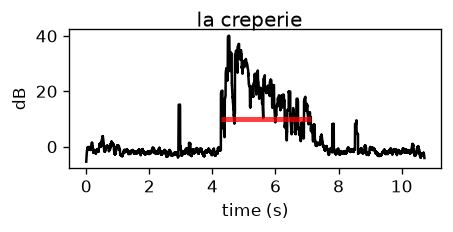

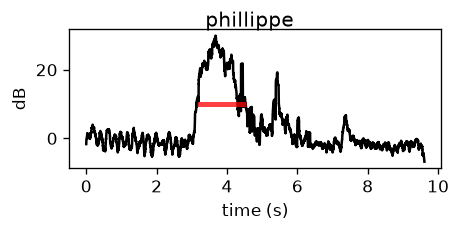

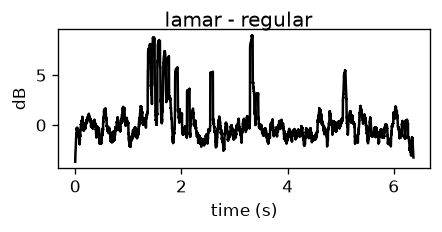

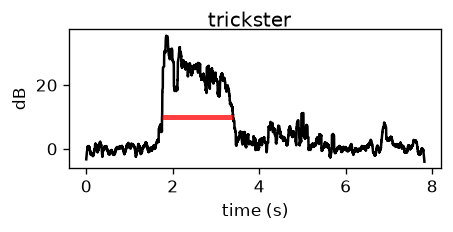

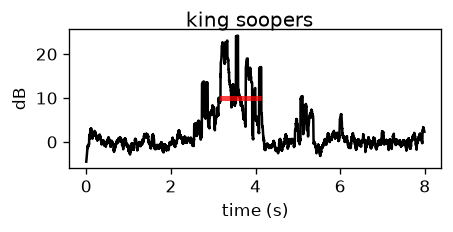

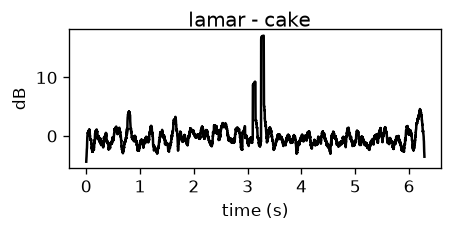

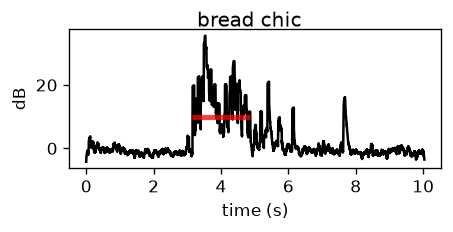

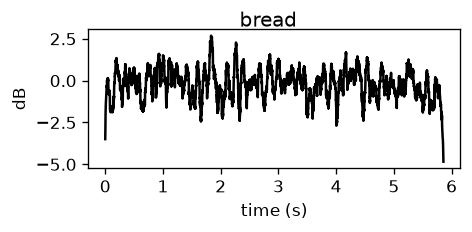

In [19]:
ref_time_block = (0.25, 1)
db_threshold = 10
smoothing_window = 0.05  # moving average over this many seconds
max_gap = 0.25  # maximum time allowed for dips in the thresholded dB to be merged
min_length = 0.5  # minimum length of the crisp to be considered real


for file in audio_files:
    name = file.name
    bakery = fname2bakery.get(name.replace("_crisp.flac", ""), None)
    if bakery is None:
        print(f"issue mapping bakery to {name}")
        continue

    # read in the audio
    audio_data, sr = read_audio_data(file)

    # remove the very beginning and end, which have some artifacts
    audio_data = audio_data.loc[int(sr * 0.5):len(audio_data)-int(sr * 1)]
    audio_data['time'] = audio_data['time'] - audio_data['time'].min()

    smoothing_kernel = np.ones(int(smoothing_window * sr))
    crisp_metrics, diagnostics = compute_crisp_metrics(
        audio_data, ref_time_block, db_threshold, smoothing_kernel=smoothing_kernel, max_gap=max_gap, min_length=min_length
    )
    all_bakery_metrics[bakery].update(**crisp_metrics)

    # plot the audio, DB & start/stop
    fig = plt.figure(figsize=(4, 1.5), dpi=120)
    fig.suptitle(bakery)
    plt.plot(audio_data['time'], diagnostics['db'], 'k')
    plt.hlines(db_threshold, diagnostics['crisp_start'], diagnostics['crisp_end'], 'r', linewidth=3, alpha=0.75)
    plt.xlabel("time (s)")
    plt.ylabel("dB")

***

## Dim Redux & Viz

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, SparsePCA, NMF

In [22]:
metrics_df = pd.DataFrame(all_bakery_metrics).T

# remove eval columns
metrics_df = metrics_df.drop(
    columns=['spring_decay_mse', 'spring_decay_r_squared', 'spring_decay_aic']
)

# derive a few additional columns
metrics_df["color_ratio_sd"] = metrics_df['color_ratio_mean'] - metrics_df["color_ratio_low"]
metrics_df["spring_decay_halflife_ratio"] = metrics_df["spring_decay_halflife"] / metrics_df["spring_decay_halflife_2"]

metrics_df = metrics_df.drop(columns=["color_ratio_low", "color_ratio_high"])
metrics_df.fillna(0, inplace=True)

,spring_decay_halflife,spring_decay_halflife_2,color_ratio_mean,rel_num_peaks,peak_size_mean,peak_size_std,cavity_size_mean,cavity_size_std,frequency_entropy,avg_crisp_db,max_crisp_db,crisp_duration,color_ratio_sd,spring_decay_halflife_ratio
bread,38.528953,38.655813,0.557927,0.098860,6.038222,5.526773,10.195971,5.651217,3.672521,0.000000,0.000000,0.000000,0.173297,0.996718
bread chic,3.503948,3.503249,0.454194,0.080461,4.768294,2.654045,11.660000,6.380000,3.054371,16.062674,35.568024,1.714333,0.114654,1.000200
king soopers,0.396011,1.734086,0.474315,0.061113,7.466892,6.539859,15.562500,8.985786,2.690113,13.220499,24.188203,1.009083,0.136241,0.228369
la creperie,2.104156,2.103681,0.456799,0.063558,6.736248,4.127058,15.717308,9.324885,2.940073,19.183582,40.086788,2.850979,0.126623,1.000226
lamar - cake,0.324933,6.637339,0.584691,0.076356,6.526965,4.388209,12.904762,5.475596,2.888451,0.000000,0.000000,0.000000,0.085636,0.048955
lamar - regular,0.322332,4.244481,0.607151,0.065365,10.727189,12.246686,14.697917,11.449308,2.247853,0.000000,0.000000,0.000000,0.071068,0.075942
phillippe,1.466207,1.466336,0.600281,0.048912,9.774151,9.221930,20.333333,15.245733,2.162688,20.448763,29.951225,1.391271,0.123190,0.999912
trickster,0.509061,2.097845,0.597282,0.062944,6.581231,4.618625,14.803419,7.347187,3.386855,23.859777,35.494619,1.641792,0.147828,0.242659


In [90]:
X = StandardScaler(with_mean=False).fit_transform(metrics_df)
# pca = SparsePCA(n_components=3, alpha=0.5)
pca = NMF(n_components=3, init='nndsvd', alpha_W=0.01, alpha_H=0.5, max_iter=1000, l1_ratio=0.5)
X = pca.fit_transform(X)
proj_df = pd.DataFrame(X, columns=[f"pc{i+1}" for i in range(pca.n_components_)])
proj_df['bakery'] = metrics_df.index

In [98]:
alt.Chart(proj_df).mark_point(filled=True, size=100).encode(
    x='pc2', y='pc3', color='bakery', tooltip=['bakery']
)

alt.Chart(...)

In [99]:
component_df = pd.DataFrame(pca.components_, columns=metrics_df.columns, index=[f"pc{i+1}" for i in range(pca.n_components_)])

In [100]:
alt.Chart(
    component_df.reset_index().melt(
        id_vars=['index'], var_name='metric', value_name='loading'
    )
).mark_bar().encode(
    x=alt.X('loading'),
    y=alt.Y('metric:N'),
    color=alt.Color("loading").scale(scheme='blues'),
    column=alt.Column('index', title='component #')
).properties(
    width=100
)

alt.Chart(...)

## Cosine (dis)similarity
An ideal croissant should be the most jointly dissimilar from all of the negative controls

In [ ]:
from sklearn.